### Importância dos Atributos (métricas intrínsecas dos modelos baseados em árvores)

Esta etapa extrai a relevância dos indicadores do IDSC a partir das métricas de importância **intrínsecas** aos algoritmos de árvore de decisão (Random Forest, XGBoost, LightGBM e CatBoost), calculadas a partir da redução de impureza ou do ganho de informação nos nós de decisão. Isso permite identificar quais indicadores mais influenciam o aprendizado dos modelos e mapear os fatores associados ao desempenho educacional (IDEB) dos municípios catarinenses.

**Como funciona (reaproveita o pipeline dos notebooks `03_global_prediction` e `partial_prediction`, sem alterá-los):**

1. Mesmos alvos (`CLASSE_AF` / `CLASSE_AI`), mesmo filtro de SC, mesma divisão treino/teste (`random_state=42`, estratificada), mesma busca de hiperparâmetros (`RandomizedSearchCV`) e mesmo tratamento de valores faltantes (imputação apenas para o Random Forest).
2. Com os melhores hiperparâmetros de cada modelo, o modelo é reajustado com várias sementes e a importância de cada atributo é **normalizada (soma = 1)** e promediada, para reduzir a instabilidade (a base de SC tem poucos municípios).
3. Métrica por algoritmo: Random Forest = redução média de impureza (Gini); XGBoost e LightGBM = **ganho** (`importance_type='gain'`); CatBoost = `PredictionValuesChange` (mudança na predição, equivalente funcional ao ganho, mas não é impureza em sentido estrito).
4. Consolidação entre modelos (média, desvio, ranking médio), agregação por ODS e exportação em CSV (arquivos **novos**, em `data/processed/`).

#### Configuração e dependências

In [1]:
import re
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import accuracy_score, f1_score
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesRegressor
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# ---------------------------------------------------------------------------
# Parâmetros da análise
# ---------------------------------------------------------------------------
MODO_ALVO = 'faixas_bruta'      # 'painel' ou 'faixas_bruta' (mesma opção dos notebooks de predição)
USAR_BALANCEAMENTO = True       # pesos balanceados por classe no treino
EXCLUIR_AGREGADOS = False       # True = remove Goal N Score / Pontuação Índice ODS das features
N_ITER = 10                     # iterações do RandomizedSearchCV (igual ao baseline)
SEMENTES = [42, 0, 1, 2, 3]     # sementes do reajuste final (estabilidade da importância)
TOP_N = 20                      # critério "apareceu no top-N" na consolidação
TOP_EXIBIR = 15                 # quantos atributos exibir nas tabelas/gráficos

MAPA_PAINEL = {'red': 'Vermelho', 'orange': 'Laranja', 'yellow': 'Amarelo', 'green': 'Verde'}
ORDEM_FAIXAS = [
    'Insuficiente / Crítico',
    'Básico / Baixo',
    'Intermediário',
    'Adequado (Meta PNE)',
    'Avançado / Alto Desempenho',
]
ORDEM_MODELOS = ['Random Forest', 'XGBoost', 'LightGBM', 'CatBoost']

base_path = Path.cwd().parent
dir_processed = base_path / "data" / "processed"

# Espaços de busca idênticos aos de 03_global_prediction / partial_prediction
ESPACOS_BUSCA = {
    'Random Forest': {
        'n_estimators': [100, 200, 300],
        'max_depth': [None, 5, 10, 15, 20],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4],
        'max_features': ['sqrt', 'log2', None],
    },
    'XGBoost': {
        'n_estimators': [100, 200, 300, 500],
        'max_depth': [3, 5, 7, 9],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    },
    'LightGBM': {
        'n_estimators': [100, 200, 300, 500],
        'num_leaves': [15, 31, 63, 127],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'subsample': [0.6, 0.8, 1.0],
        'colsample_bytree': [0.6, 0.8, 1.0],
    },
    'CatBoost': {
        'iterations': [200, 400, 600],
        'depth': [4, 6, 8, 10],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'l2_leaf_reg': [1, 3, 5, 7],
    },
}


def carregar_alvos_ideb():
    """Lê a nota bruta e o Painel do IDEB (AF/AI), indexados por id_municipio."""
    return pd.read_csv(dir_processed / "Base_de_Alvos_IDEB.csv", index_col='id_municipio')


def rotular_classes(alvos, ab):
    """Devolve, por id_municipio, o rótulo da classe ('af' = Anos Finais, 'ai' = Anos Iniciais)."""
    if MODO_ALVO == 'painel':
        return alvos[f'painel_{ab}'].map(MAPA_PAINEL)
    nota_x10 = (alvos[f'ideb_{ab}_bruto'] * 10).round(4)
    faixas = pd.cut(nota_x10, bins=[-np.inf, 40, 50, 60, 70, np.inf], labels=ORDEM_FAIXAS, right=False)
    return faixas.astype(object)


def classificar_atributo(nome):
    """'Agregado' = escores que já resumem vários indicadores (Goal N Score, Pontuação Índice ODS...)."""
    if re.search(r'Goal \d+ Score|Pontuação Indice ODS|ODS\d+_reg', str(nome)):
        return 'Agregado'
    return 'Indicador'


def rotular_ods(nome):
    if classificar_atributo(nome) == 'Agregado':
        return 'Escores agregados'
    m = re.search(r'SDG(\d+)', str(nome))
    return f'ODS {int(m.group(1))}' if m else 'Outros (demografia etc.)'

#### Carregamento das bases (global e parcial) — apenas municípios de SC

In [2]:
file_path = dir_processed / "Base_de_Dados_Processada.csv"
raw_path = base_path / "data" / "raw" / "Base_de_Dados_IDSC-BR_2025.xlsx"

target_col_ideb_af = 'Normalizado (0-100): SDG4_15_IDEB_AF'
target_col_ideb_ai = 'Normalizado (0-100): SDG4_16_IDEB_AI'
classe_af, classe_ai = 'CLASSE_AF', 'CLASSE_AI'

# Filtro de SC (UF vem da planilha bruta; não entra como feature)
uf_por_municipio = pd.read_excel(raw_path, sheet_name="Todos os Dados", usecols=["ID", "UF"])
uf_por_municipio = uf_por_municipio.rename(columns={"ID": "id_municipio"})
ids_sc = uf_por_municipio.loc[uf_por_municipio["UF"] == "SC", "id_municipio"]

alvos_ideb = carregar_alvos_ideb()


def anexar_alvos(df_base):
    df_base = df_base[df_base["id_municipio"].isin(ids_sc)].reset_index(drop=True)
    df_base[classe_af] = df_base['id_municipio'].map(rotular_classes(alvos_ideb, 'af'))
    df_base[classe_ai] = df_base['id_municipio'].map(rotular_classes(alvos_ideb, 'ai'))
    return df_base


# Base global (todas as variáveis)
df_global = anexar_alvos(pd.read_csv(file_path))

# Base parcial (features selecionadas)
with open(dir_processed / "features_selecionadas_sc.json", "r", encoding="utf-8") as arquivo:
    features_sel = json.load(arquivo)

cols_parcial = [target_col_ideb_af, target_col_ideb_ai] + list(features_sel)
if 'id_municipio' not in cols_parcial:
    cols_parcial.append('id_municipio')
df_parcial = anexar_alvos(pd.read_csv(file_path, usecols=cols_parcial))

# Colunas que NÃO podem virar feature (alvos + identificador)
colunas_alvo = [target_col_ideb_af, target_col_ideb_ai, classe_af, classe_ai, 'id_municipio']

print(f"Global:  {df_global.shape[0]} municípios x {df_global.shape[1] - len(colunas_alvo)} atributos")
print(f"Parcial: {df_parcial.shape[0]} municípios x {df_parcial.shape[1] - len(colunas_alvo)} atributos")

Global:  295 municípios x 132 atributos
Parcial: 295 municípios x 105 atributos


#### Função de extração das importâncias

Replica o pré-processamento e a avaliação do baseline (mesma divisão, mesmos pesos, mesma busca) e, **depois** de escolher os melhores hiperparâmetros, reajusta cada modelo com várias sementes para extrair `feature_importances_`. As colunas são sanitizadas só para o treino (exigência do LightGBM/XGBoost); os nomes originais são restaurados nos resultados.

In [3]:
def normalizar(v):
    v = np.asarray(v, dtype=float)
    s = v.sum()
    return v / s if s > 0 else v


def calcular_importancias(df_base, coluna_alvo, nome_base, nome_alvo):
    df_clean = df_base.dropna(subset=[coluna_alvo])
    remover = [c for c in colunas_alvo if c in df_clean.columns]
    X = df_clean.drop(columns=remover, errors='ignore')

    if EXCLUIR_AGREGADOS:
        X = X.drop(columns=[c for c in X.columns if classificar_atributo(c) == 'Agregado'])

    nomes_originais = list(X.columns)
    X.columns = [re.sub(r'[^a-zA-Z0-9_]', '_', str(c)) for c in X.columns]
    if X.columns.duplicated().any():
        raise ValueError("Nomes de colunas colidiram após a sanitização; ajuste a regex.")

    y_raw = df_clean[coluna_alvo].astype(str)
    contagem = y_raw.value_counts()
    mask = y_raw.isin(contagem[contagem >= 2].index)
    X, y_raw = X[mask], y_raw[mask]

    le = LabelEncoder()
    y = le.fit_transform(y_raw)
    print(f"\n--- {nome_base} | {nome_alvo} | classes: {list(le.classes_)} | n={len(y)} | atributos={X.shape[1]}")

    try:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    except ValueError:
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

    sw = compute_sample_weight('balanced', y_train) if USAR_BALANCEAMENTO else None
    n_splits = max(2, min(3, pd.Series(y_train).value_counts().min()))
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

    imputer_rf = IterativeImputer(estimator=ExtraTreesRegressor(n_estimators=10, random_state=42), random_state=42)
    X_train_rf = pd.DataFrame(imputer_rf.fit_transform(X_train), columns=X_train.columns, index=X_train.index)
    X_test_rf = pd.DataFrame(imputer_rf.transform(X_test), columns=X_test.columns, index=X_test.index)

    # XGBoost e LightGBM: importance_type='gain' (o padrão do LightGBM seria 'split' = nº de usos)
    modelos = {
        'Random Forest': RandomForestClassifier(random_state=42),
        'XGBoost': XGBClassifier(random_state=42, eval_metric='logloss', importance_type='gain'),
        'LightGBM': LGBMClassifier(random_state=42, verbose=-1, importance_type='gain'),
        'CatBoost': CatBoostClassifier(random_state=42, verbose=0),
    }

    linhas, desempenho = [], []
    for nome, modelo in modelos.items():
        X_tr, X_te = (X_train_rf, X_test_rf) if nome == 'Random Forest' else (X_train, X_test)
        busca = RandomizedSearchCV(modelo, ESPACOS_BUSCA[nome], n_iter=N_ITER, scoring='accuracy',
                                   cv=cv, random_state=42, n_jobs=1, error_score='raise')
        try:
            busca.fit(X_tr, y_train, sample_weight=sw)
            melhor = busca.best_estimator_
            y_pred = melhor.predict(X_te)
            desempenho.append({
                'Base': nome_base, 'Alvo': nome_alvo, 'Modelo': nome,
                'Acurácia (teste)': accuracy_score(y_test, y_pred),
                'F1 Macro (teste)': f1_score(y_test, y_pred, average='macro'),
                'Melhores hiperparâmetros': str(busca.best_params_),
            })

            imps = []
            for semente in SEMENTES:
                m = clone(melhor).set_params(random_state=semente)
                m.fit(X_tr, y_train, sample_weight=sw)
                imps.append(normalizar(m.feature_importances_))
            imps = np.vstack(imps)

            linhas.append(pd.DataFrame({
                'Base': nome_base, 'Alvo': nome_alvo, 'Modelo': nome,
                'Atributo': nomes_originais,
                'Importancia': imps.mean(axis=0),
                'Desvio_sementes': imps.std(axis=0),
            }))
        except Exception as e:
            print(f"Aviso: {nome} falhou para '{nome_alvo}' ({nome_base}) — pulando. Erro: {e}")

    return (pd.concat(linhas, ignore_index=True) if linhas else pd.DataFrame()), pd.DataFrame(desempenho)

#### Execução: Base global e base parcial × Anos Finais (AF) e Anos Iniciais (AI)

In [4]:
execucoes = [
    ('Global (todas as variáveis)', df_global, classe_af, 'AF'),
    ('Global (todas as variáveis)', df_global, classe_ai, 'AI'),
    ('Parcial (selecionadas)', df_parcial, classe_af, 'AF'),
    ('Parcial (selecionadas)', df_parcial, classe_ai, 'AI'),
]

lista_imp, lista_desemp = [], []
for nome_base, df_base, col_alvo, nome_alvo in execucoes:
    imp, desemp = calcular_importancias(df_base, col_alvo, nome_base, nome_alvo)
    lista_imp.append(imp)
    lista_desemp.append(desemp)

imp_longo = pd.concat(lista_imp, ignore_index=True)
desempenho = pd.concat(lista_desemp, ignore_index=True)

display(desempenho.drop(columns=['Melhores hiperparâmetros']).round(4))


--- Global (todas as variáveis) | AF | classes: ['Adequado (Meta PNE)', 'Básico / Baixo', 'Insuficiente / Crítico', 'Intermediário'] | n=151 | atributos=132

--- Global (todas as variáveis) | AI | classes: ['Adequado (Meta PNE)', 'Avançado / Alto Desempenho', 'Intermediário'] | n=272 | atributos=132

--- Parcial (selecionadas) | AF | classes: ['Adequado (Meta PNE)', 'Básico / Baixo', 'Insuficiente / Crítico', 'Intermediário'] | n=151 | atributos=105

--- Parcial (selecionadas) | AI | classes: ['Adequado (Meta PNE)', 'Avançado / Alto Desempenho', 'Intermediário'] | n=272 | atributos=105


,Base,Alvo,Modelo,Acurácia (teste),F1 Macro (teste)
0,Global (todas as variáveis),AF,Random Forest,0.5806,0.3177
1,Global (todas as variáveis),AF,XGBoost,0.6129,0.4267
2,Global (todas as variáveis),AF,LightGBM,0.6452,0.4683
3,Global (todas as variáveis),AF,CatBoost,0.5806,0.3957
4,Global (todas as variáveis),AI,Random Forest,0.6727,0.4117
5,Global (todas as variáveis),AI,XGBoost,0.7273,0.5563
6,Global (todas as variáveis),AI,LightGBM,0.7091,0.5909
7,Global (todas as variáveis),AI,CatBoost,0.6182,0.5582
8,Parcial (selecionadas),AF,Random Forest,0.5161,0.2819
9,Parcial (selecionadas),AF,XGBoost,0.5806,0.3333


#### Consolidação entre modelos

Para cada combinação base × alvo: importância média (já normalizada por modelo), desvio entre modelos, ranking médio e em quantos modelos o atributo aparece entre os `TOP_N` mais importantes. Atributos que aparecem no topo em vários algoritmos são os mais confiáveis.

In [5]:
def consolidar(imp_longo):
    modelos = [m for m in ORDEM_MODELOS if m in imp_longo['Modelo'].unique()]
    piv = imp_longo.pivot_table(index=['Base', 'Alvo', 'Atributo'], columns='Modelo', values='Importancia')[modelos]

    ranks = piv.groupby(level=['Base', 'Alvo']).rank(ascending=False, method='min')
    out = piv.copy()
    out['Média'] = piv.mean(axis=1)
    out['Desvio entre modelos'] = piv.std(axis=1)
    out['Rank médio'] = ranks.mean(axis=1)
    out[f'Modelos no top-{TOP_N}'] = (ranks <= TOP_N).sum(axis=1)
    out = out.reset_index()
    out['Tipo'] = out['Atributo'].map(classificar_atributo)
    out['ODS'] = out['Atributo'].map(rotular_ods)
    return out.sort_values(['Base', 'Alvo', 'Média'], ascending=[True, True, False]), modelos


consolidado, modelos_ok = consolidar(imp_longo)

for (base, alvo), g in consolidado.groupby(['Base', 'Alvo'], sort=False):
    print(f"\n=== {base} | {alvo} — top {TOP_EXIBIR} ===")
    display(g.head(TOP_EXIBIR)[['Atributo', 'Tipo', 'ODS'] + modelos_ok +
                               ['Média', 'Rank médio', f'Modelos no top-{TOP_N}']].round(4).reset_index(drop=True))


=== Global (todas as variáveis) | AF — top 15 ===


Modelo,Atributo,Tipo,ODS,Random Forest,XGBoost,LightGBM,CatBoost,Média,Rank médio,Modelos no top-20
0,Normalizado (0-100): SDG2_3_DSNT_INF,Indicador,ODS 2,0.1201,0.0170,0.0524,0.0419,0.0579,5.00,4
1,Normalizado (0-100): SDG4_17_JV_EM,Indicador,ODS 4,0.0775,0.0289,0.0741,0.0176,0.0495,2.75,4
2,Normalizado (0-100): SDG3_6_ID_MD_M,Indicador,ODS 3,0.0387,0.0276,0.1041,0.0240,0.0486,2.75,4
3,Normalizado (0-100): SDG3_3_P_NV_7PN,Indicador,ODS 3,0.0664,0.0189,0.0704,0.0280,0.0459,4.50,4
4,Normalizado (0-100): SDG3_9_INC_TRB,Indicador,ODS 3,0.0183,0.0142,0.0659,0.0234,0.0304,9.50,4
5,Normalizado (0-100): SDG5_7_JV_NENT,Indicador,ODS 5,0.0225,0.0201,0.0587,0.0139,0.0288,9.50,4
6,Normalizado (0-100): SDG3_19_T_M_AIDS,Indicador,ODS 3,0.0090,0.0207,0.0455,0.0157,0.0227,11.75,3
7,Pontuação Indice ODS 2025,Agregado,Escores agregados,0.0478,0.0109,0.0148,0.0164,0.0225,15.25,3
8,Normalizado (0-100): SDG15_2_FLOR,Indicador,ODS 15,0.0272,0.0253,0.0192,0.0147,0.0216,9.00,4
9,Normalizado (0-100): SDG6_4_PRD_AG,Indicador,ODS 6,0.0239,0.0094,0.0305,0.0143,0.0195,17.50,3



=== Global (todas as variáveis) | AI — top 15 ===


Modelo,Atributo,Tipo,ODS,Random Forest,XGBoost,LightGBM,CatBoost,Média,Rank médio,Modelos no top-20
0,Normalizado (0-100): SDG4_3_TDI_EF_RP,Indicador,ODS 4,0.1759,0.0304,0.1625,0.1326,0.1253,1.00,4
1,Normalizado (0-100): SDG5_7_JV_NENT,Indicador,ODS 5,0.0358,0.0185,0.0506,0.0291,0.0335,4.75,4
2,Goal 5 Score,Agregado,Escores agregados,0.0392,0.0213,0.0331,0.0313,0.0312,3.50,4
3,Pontuação Indice ODS 2025,Agregado,Escores agregados,0.0390,0.0146,0.0393,0.0309,0.0310,5.00,4
4,Normalizado (0-100): SDG8_3_T_DSC,Indicador,ODS 8,0.0407,0.0203,0.0331,0.0252,0.0298,5.00,4
5,Normalizado (0-100): SDG5_3_M_JV_NENT,Indicador,ODS 5,0.0329,0.0224,0.0240,0.0278,0.0268,5.75,4
6,Normalizado (0-100): SDG9_2_EMP_INT,Indicador,ODS 9,0.0231,0.0184,0.0319,0.0131,0.0216,10.00,4
7,Normalizado (0-100): SDG11_5_EQP_ESP,Indicador,ODS 11,0.0137,0.0123,0.0312,0.0227,0.0200,12.00,4
8,Normalizado (0-100): SDG8_7_P_JV_NENT,Indicador,ODS 8,0.0193,0.0211,0.0114,0.0236,0.0189,11.75,3
9,Normalizado (0-100): SDG3_22_T_M_DC,Indicador,ODS 3,0.0307,0.0088,0.0159,0.0164,0.0180,19.75,3



=== Parcial (selecionadas) | AF — top 15 ===


Modelo,Atributo,Tipo,ODS,Random Forest,XGBoost,LightGBM,CatBoost,Média,Rank médio,Modelos no top-20
0,Normalizado (0-100): SDG3_6_ID_MD_M,Indicador,ODS 3,0.0358,0.0409,0.1405,0.0419,0.0648,1.75,4
1,Normalizado (0-100): SDG3_9_INC_TRB,Indicador,ODS 3,0.0293,0.0244,0.1078,0.0352,0.0492,4.25,4
2,Normalizado (0-100): SDG5_7_JV_NENT,Indicador,ODS 5,0.0273,0.0485,0.0944,0.0263,0.0491,4.00,4
3,Normalizado (0-100): SDG2_3_DSNT_INF,Indicador,ODS 2,0.0360,0.0251,0.0543,0.0563,0.0430,3.25,4
4,Normalizado (0-100): SDG3_3_P_NV_7PN,Indicador,ODS 3,0.0324,0.0190,0.0801,0.0361,0.0419,5.00,4
5,Normalizado (0-100): SDG3_19_T_M_AIDS,Indicador,ODS 3,0.0211,0.0266,0.0766,0.0342,0.0396,6.50,4
6,Normalizado (0-100): SDG3_18_T_M_NT,Indicador,ODS 3,0.0166,0.0199,0.0384,0.0157,0.0227,14.25,3
7,Normalizado (0-100): SDG6_4_PRD_AG,Indicador,ODS 6,0.0219,0.0199,0.0275,0.0203,0.0224,9.75,4
8,Normalizado (0-100): SDG15_2_FLOR,Indicador,ODS 15,0.0214,0.0268,0.0223,0.0185,0.0222,9.50,4
9,Pontuação Indice ODS 2025,Agregado,Escores agregados,0.0275,0.0116,0.0211,0.0245,0.0212,14.00,3



=== Parcial (selecionadas) | AI — top 15 ===


Modelo,Atributo,Tipo,ODS,Random Forest,XGBoost,LightGBM,CatBoost,Média,Rank médio,Modelos no top-20
0,Goal 5 Score,Agregado,Escores agregados,0.0368,0.0362,0.0791,0.0528,0.0512,2.00,4
1,Pontuação Indice ODS 2025,Agregado,Escores agregados,0.0399,0.0199,0.0772,0.0542,0.0478,2.50,4
2,Normalizado (0-100): SDG11_5_EQP_ESP,Indicador,ODS 11,0.0267,0.0183,0.0772,0.0321,0.0386,6.50,4
3,Normalizado (0-100): SDG5_7_JV_NENT,Indicador,ODS 5,0.0487,0.0189,0.0297,0.0459,0.0358,4.50,4
4,Normalizado (0-100): SDG8_7_P_JV_NENT,Indicador,ODS 8,0.0384,0.0273,0.0300,0.0372,0.0332,3.75,4
5,Normalizado (0-100): SDG9_2_EMP_INT,Indicador,ODS 9,0.0273,0.0182,0.0622,0.0239,0.0329,7.25,4
6,Normalizado (0-100): SDG3_3_P_NV_7PN,Indicador,ODS 3,0.0278,0.0149,0.0212,0.0340,0.0245,11.75,4
7,Goal 11 Score,Agregado,Escores agregados,0.0305,0.0163,0.0182,0.0314,0.0241,11.00,4
8,Normalizado (0-100): SDG3_6_ID_MD_M,Indicador,ODS 3,0.0221,0.0160,0.0378,0.0174,0.0233,11.25,4
9,Normalizado (0-100): SDG2_3_DSNT_INF,Indicador,ODS 2,0.0244,0.0144,0.0268,0.0207,0.0216,14.25,3


#### Gráficos: atributos mais relevantes (média entre modelos) e comparação entre algoritmos

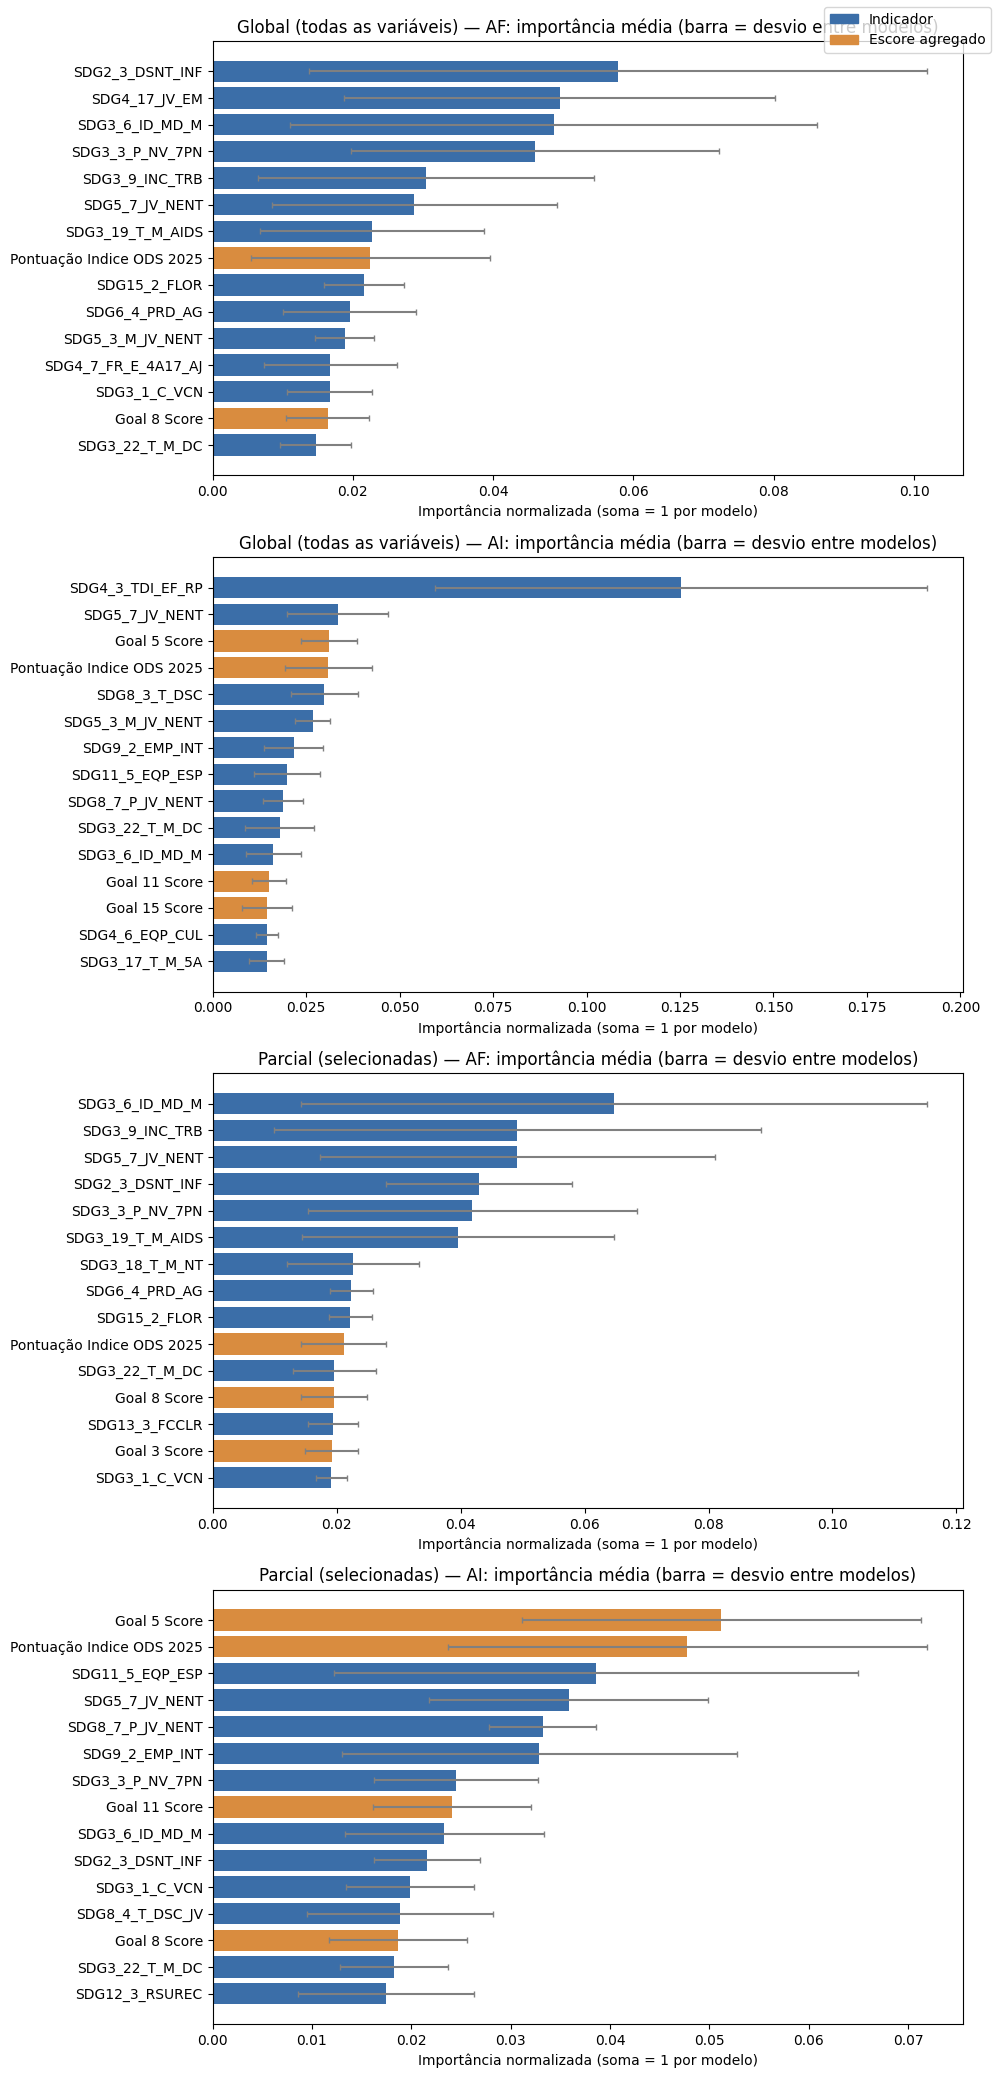

In [6]:
def rotulo_curto(nome, n=55):
    nome = re.sub(r'^Normalizado \(0-100\):\s*', '', str(nome))
    return nome if len(nome) <= n else nome[:n - 1] + '…'


combinacoes = list(consolidado.groupby(['Base', 'Alvo'], sort=False))
fig, axes = plt.subplots(len(combinacoes), 1, figsize=(10, 5.2 * len(combinacoes)))
axes = np.atleast_1d(axes)

for ax, ((base, alvo), g) in zip(axes, combinacoes):
    top = g.head(TOP_EXIBIR).iloc[::-1]
    cores = ['#d98c3f' if t == 'Agregado' else '#3b6ea8' for t in top['Tipo']]
    ax.barh([rotulo_curto(a) for a in top['Atributo']], top['Média'],
            xerr=top['Desvio entre modelos'].fillna(0), color=cores, ecolor='gray', capsize=2)
    ax.set_title(f"{base} — {alvo}: importância média (barra = desvio entre modelos)")
    ax.set_xlabel("Importância normalizada (soma = 1 por modelo)")

from matplotlib.patches import Patch
fig.legend(handles=[Patch(color='#3b6ea8', label='Indicador'), Patch(color='#d98c3f', label='Escore agregado')],
           loc='upper right')
plt.tight_layout()
plt.show()

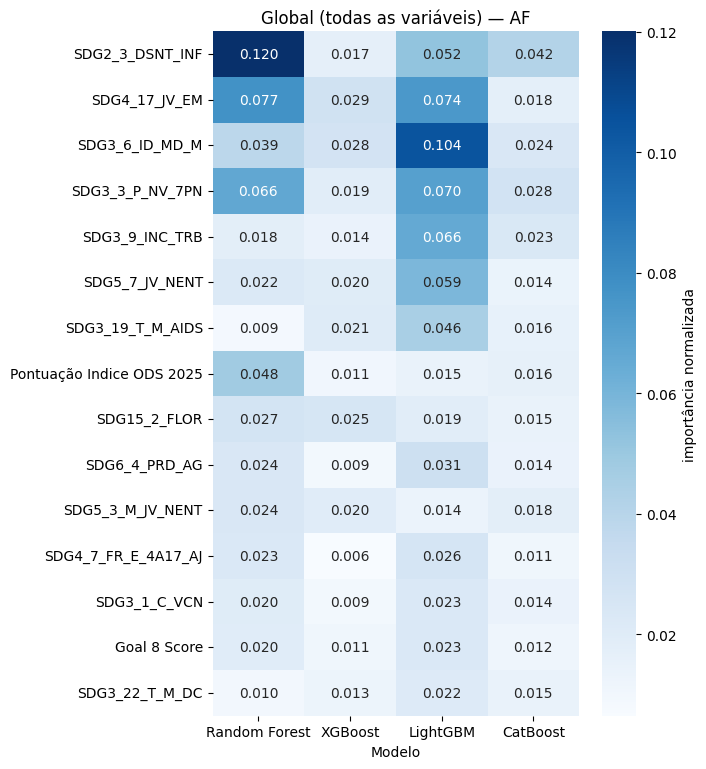

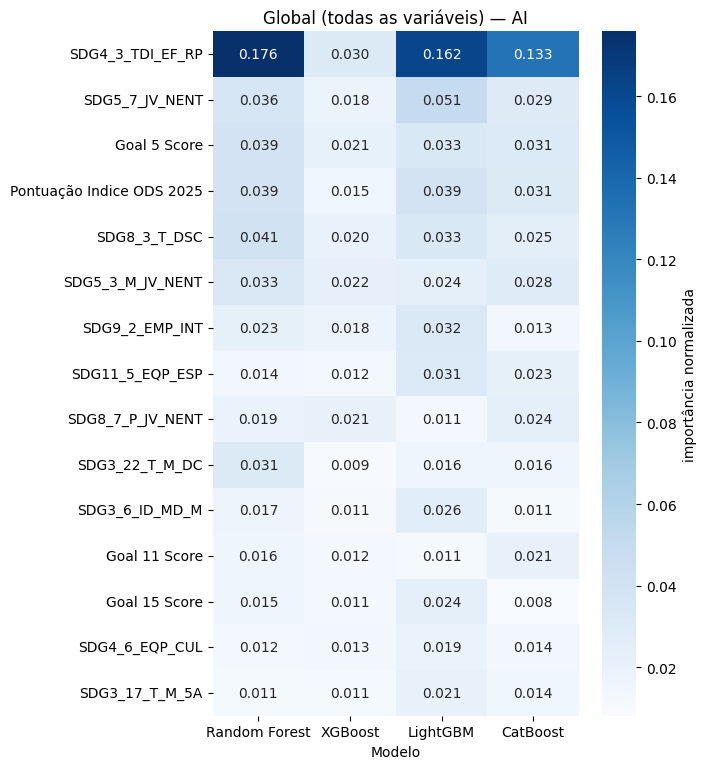

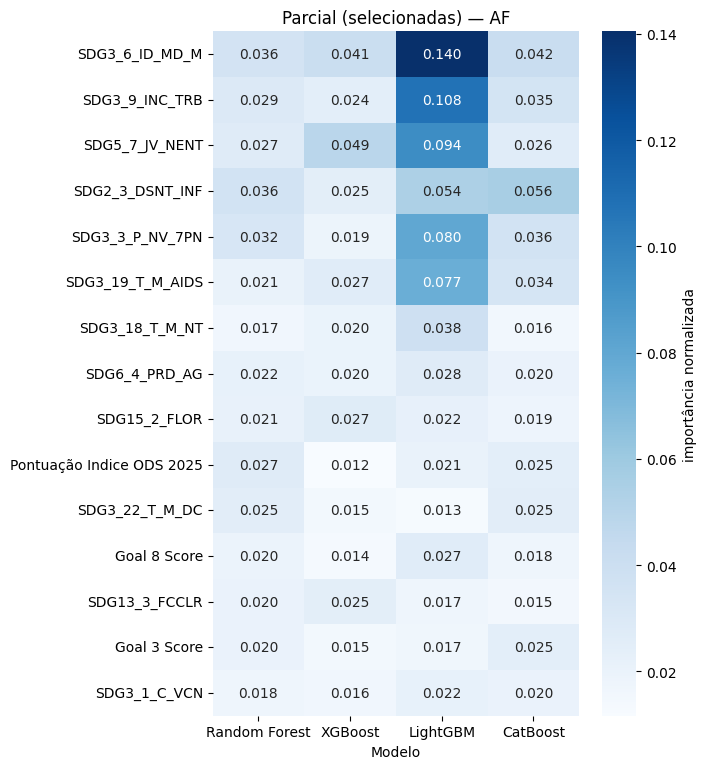

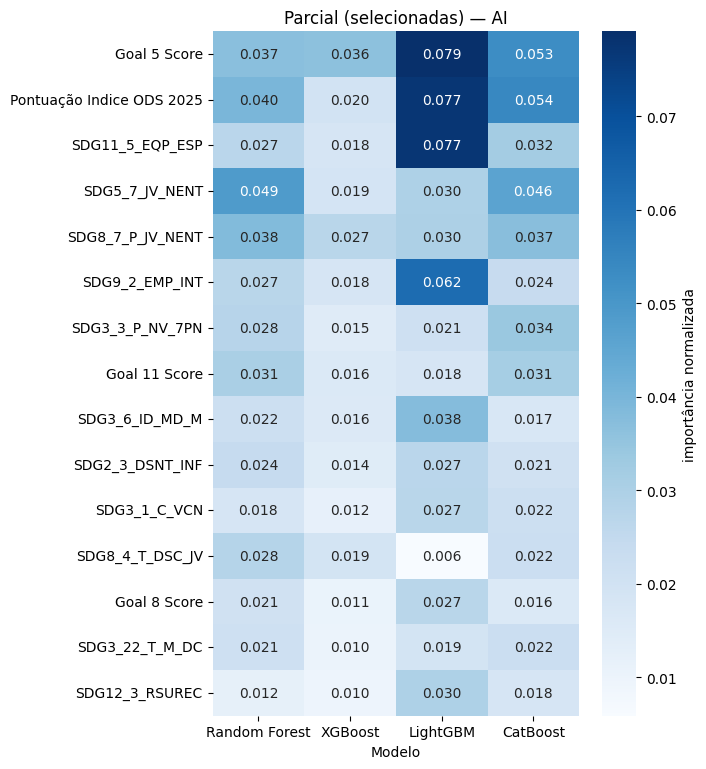

In [7]:
# Heatmap: concordância entre algoritmos nos atributos do top (rank médio)
for (base, alvo), g in combinacoes:
    top = g.head(TOP_EXIBIR)
    mat = top.set_index(top['Atributo'].map(rotulo_curto))[modelos_ok]
    plt.figure(figsize=(7, 0.42 * len(mat) + 1.5))
    sns.heatmap(mat, annot=True, fmt='.3f', cmap='Blues', cbar_kws={'label': 'importância normalizada'})
    plt.title(f"{base} — {alvo}")
    plt.ylabel('')
    plt.tight_layout()
    plt.show()

#### Importância agregada por ODS

Soma da importância média dos indicadores de cada ODS (escores agregados como `Goal N Score` ficam em um grupo separado para não contar duas vezes os mesmos indicadores). Mostra **em qual dimensão do desenvolvimento sustentável** está concentrada a informação usada pelos modelos para prever o IDEB.


=== Global (todas as variáveis) | AF ===


,Base,Alvo,ODS,Importância agregada
0,Global (todas as variáveis),AF,ODS 3,0.2580
1,Global (todas as variáveis),AF,ODS 4,0.1596
2,Global (todas as variáveis),AF,Escores agregados,0.1232
3,Global (todas as variáveis),AF,ODS 2,0.0817
4,Global (todas as variáveis),AF,ODS 5,0.0599
5,Global (todas as variáveis),AF,ODS 10,0.0463
6,Global (todas as variáveis),AF,ODS 6,0.0396
7,Global (todas as variáveis),AF,ODS 8,0.0392
8,Global (todas as variáveis),AF,ODS 1,0.0326
9,Global (todas as variáveis),AF,ODS 13,0.0322



=== Global (todas as variáveis) | AI ===


,Base,Alvo,ODS,Importância agregada
0,Global (todas as variáveis),AI,ODS 4,0.2144
1,Global (todas as variáveis),AI,Escores agregados,0.1885
2,Global (todas as variáveis),AI,ODS 3,0.1396
3,Global (todas as variáveis),AI,ODS 8,0.0791
4,Global (todas as variáveis),AI,ODS 5,0.0689
5,Global (todas as variáveis),AI,ODS 2,0.0466
6,Global (todas as variáveis),AI,ODS 11,0.0388
7,Global (todas as variáveis),AI,ODS 6,0.0380
8,Global (todas as variáveis),AI,ODS 10,0.0353
9,Global (todas as variáveis),AI,ODS 13,0.0292



=== Parcial (selecionadas) | AF ===


,Base,Alvo,ODS,Importância agregada
0,Parcial (selecionadas),AF,ODS 3,0.3222
1,Parcial (selecionadas),AF,Escores agregados,0.1325
2,Parcial (selecionadas),AF,ODS 2,0.0696
3,Parcial (selecionadas),AF,ODS 5,0.0655
4,Parcial (selecionadas),AF,ODS 10,0.0572
5,Parcial (selecionadas),AF,ODS 13,0.0540
6,Parcial (selecionadas),AF,ODS 6,0.0538
7,Parcial (selecionadas),AF,ODS 8,0.0485
8,Parcial (selecionadas),AF,ODS 15,0.0331
9,Parcial (selecionadas),AF,ODS 11,0.0311



=== Parcial (selecionadas) | AI ===


,Base,Alvo,ODS,Importância agregada
0,Parcial (selecionadas),AI,Escores agregados,0.2374
1,Parcial (selecionadas),AI,ODS 3,0.1797
2,Parcial (selecionadas),AI,ODS 8,0.0820
3,Parcial (selecionadas),AI,ODS 2,0.0681
4,Parcial (selecionadas),AI,ODS 11,0.0673
5,Parcial (selecionadas),AI,ODS 10,0.0509
6,Parcial (selecionadas),AI,ODS 5,0.0499
7,Parcial (selecionadas),AI,ODS 6,0.0474
8,Parcial (selecionadas),AI,ODS 13,0.0416
9,Parcial (selecionadas),AI,ODS 9,0.0406


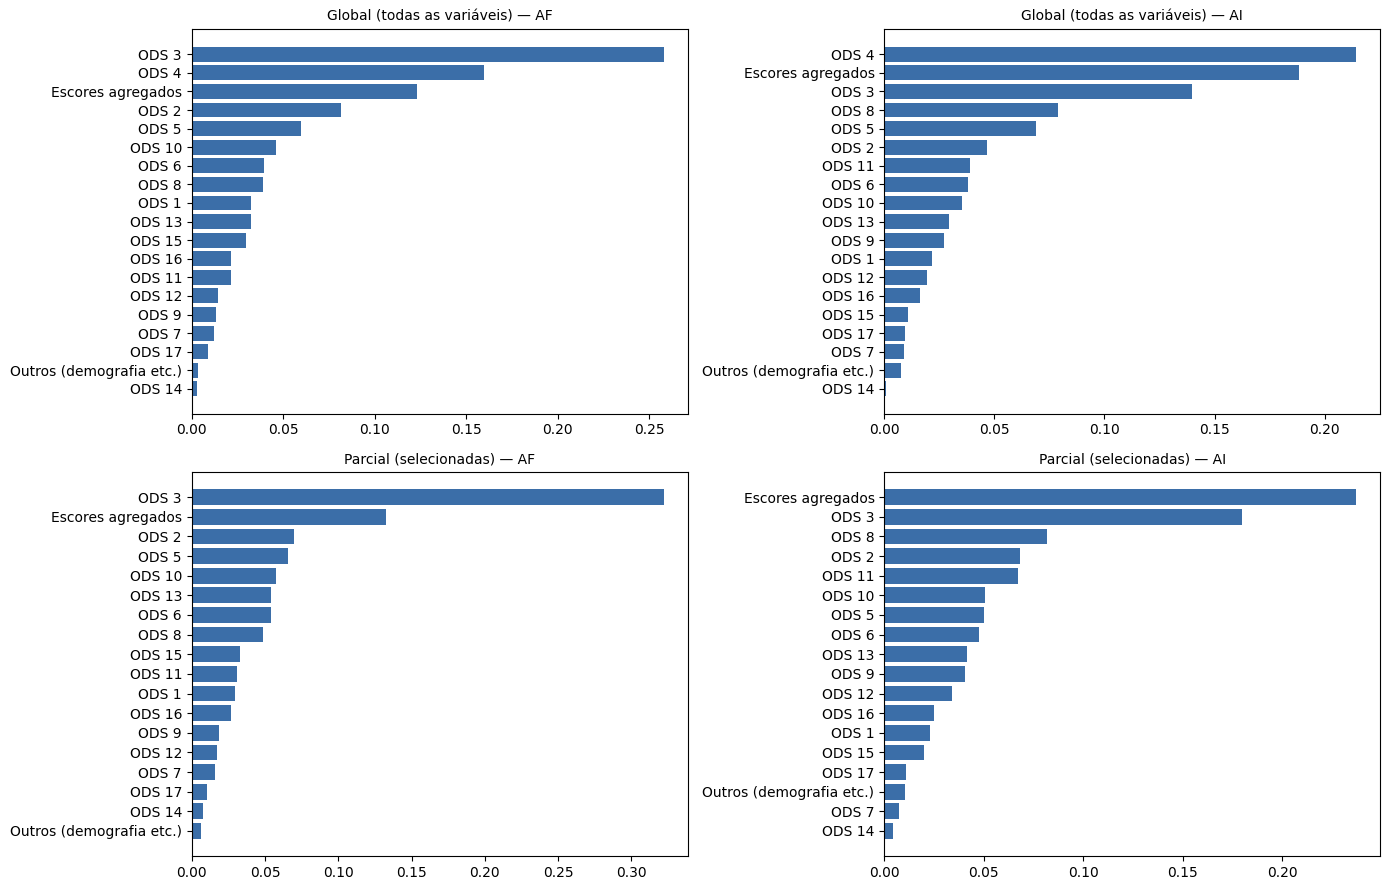

In [8]:
por_ods = (consolidado.groupby(['Base', 'Alvo', 'ODS'], as_index=False)['Média'].sum()
           .rename(columns={'Média': 'Importância agregada'}))

for (base, alvo), g in por_ods.groupby(['Base', 'Alvo'], sort=False):
    g = g.sort_values('Importância agregada', ascending=False)
    print(f"\n=== {base} | {alvo} ===")
    display(g.round(4).reset_index(drop=True))

fig, axes = plt.subplots(2, 2, figsize=(14, 9), sharex=False)
for ax, ((base, alvo), g) in zip(axes.ravel(), por_ods.groupby(['Base', 'Alvo'], sort=False)):
    g = g.sort_values('Importância agregada')
    ax.barh(g['ODS'], g['Importância agregada'], color='#3b6ea8')
    ax.set_title(f"{base} — {alvo}", fontsize=10)
plt.tight_layout()
plt.show()

#### Exportação (arquivos novos; nenhum arquivo existente é sobrescrito)

In [9]:
imp_longo.to_csv(dir_processed / "importancia_atributos_por_modelo.csv", index=False)
consolidado.to_csv(dir_processed / "importancia_atributos_consolidada.csv", index=False)
por_ods.to_csv(dir_processed / "importancia_agregada_por_ods.csv", index=False)
desempenho.to_csv(dir_processed / "importancia_desempenho_modelos.csv", index=False)

print("Arquivos salvos em:", dir_processed)

Arquivos salvos em: /home/clara/Desktop/idsc-analysis/data/processed


#### Como interpretar (limitações)

- **Importância ≠ causalidade.** Indica o quanto o modelo usa o atributo para separar as classes de IDEB, não que mexer nele mude o IDEB.
- **Qualidade do modelo.** Com acurácia moderada (próxima de 0,55–0,60), as importâncias descrevem o que o modelo aprendeu, não necessariamente a "verdade" do fenômeno. Compare sempre com a tabela de desempenho.
- **Poucos municípios (≈295 em SC) e muitos atributos:** a importância é instável; por isso o reajuste com várias sementes e a consolidação entre quatro algoritmos. Priorize atributos que aparecem no topo em vários modelos.
- **Atributos correlacionados dividem a importância** entre si (um indicador pode parecer menos relevante só porque tem "gêmeos"). A base parcial, que já passou pela remoção de multicolinearidade, tende a ser mais fácil de ler.
- **Viés das métricas de impureza/ganho:** favorecem variáveis contínuas com muitos valores distintos. Se necessário, confirme o ranking com importância por permutação (fora do escopo desta etapa).
- **Escores agregados** (`Goal N Score`, `Pontuação Indice ODS 2025`) resumem vários indicadores e podem concentrar importância; `Pontuação Indice ODS 2025` inclui o ODS 4 e, portanto, pode carregar informação do próprio IDEB. Use `EXCLUIR_AGREGADOS = True` para ver o ranking apenas com indicadores.